In [ ]:
# the final epoch for unfreez 9
https://drive.google.com/file/d/10TysYr0w6PjrvxJanNWK4C1eAvDjYBBA/view?usp=sharing

In [ ]:
import os
import json
import random
import math

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from torchvision.models.mobilenetv3 import mobilenet_v3_small

import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split
from tqdm import tqdm

In [ ]:
# Configurations


In [ ]:
# Data config
DATA_PATH = '/content'
PIC_PATH = os.path.join(DATA_PATH, 'crop_pic')
TRAIN_PROP = 0.8

# Checkpoints config
SAVE_TO = '/content/drive/MyDrive/cblur/'
LOAD_CHECKPOINT = True
#CHECKPOINT_PATH = os.path.join(SAVE_TO, 'cpcolor_1.pth ')
CHECKPOINT_PATH="/content/drive/MyDrive/mgded/cpcolor_69.pth"
# Train config
LR = 1e-4
BATCH_SIZE = 1<<8
L2_FACTOR = 1e-4
LAST_EPOCH = 100

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
model = PoseEstimationWithBackbone().to(device)
checkpoint = torch.load(CHECKPOINT_PATH)
model.load_state_dict(checkpoint['model_state_dict'])
start_epoch = checkpoint['epoch']
tr_loss = checkpoint["test_loss"]
tr_loss = checkpoint["train_loss"]
print(start_epoch)

In [ ]:
!wget https://www.7-zip.org/a/7z2301-linux-x64.tar.xz

--2024-01-25 08:22:45--  https://www.7-zip.org/a/7z2301-linux-x64.tar.xz
Resolving www.7-zip.org (www.7-zip.org)... 49.12.202.237
Connecting to www.7-zip.org (www.7-zip.org)|49.12.202.237|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1527700 (1.5M) [application/octet-stream]
Saving to: ‘7z2301-linux-x64.tar.xz’

7z2301-linux-x64.ta 100%[===================>]   1.46M  1.60MB/s    in 0.9s    

2024-01-25 08:22:47 (1.60 MB/s) - ‘7z2301-linux-x64.tar.xz’ saved [1527700/1527700]



In [ ]:
!tar -xf /content/7z2301-linux-x64.tar.xz

In [ ]:
!/content/7zz x /content/drive/MyDrive/crop_label1.zip -o/content/


7-Zip (z) 23.01 (x64) : Copyright (c) 1999-2023 Igor Pavlov : 2023-06-20
 64-bit locale=en_US.UTF-8 Threads:2 OPEN_MAX:1048576, ASM

Scanning the drive for archives:
  0M Scan /content/drive/MyDrive/                                 1 file, 51384979 bytes (50 MiB)

Extracting archive: /content/drive/MyDrive/crop_label1.zip
  2% 4096 Open              --
Path = /content/drive/MyDrive/crop_label1.zip
Type = zip
Physical Size = 51384979
64-bit = +
Characteristics = Zip64

  0%      2% 3512           4% 7197 - crop_label/00002540.rgb_7197.json                                               6% 10978 - crop_label/00003891.rgb_10978.json                                                 8% 13715

In [ ]:
!/content/7zz x /content/drive/MyDrive/crop_pic.zip -o/content/


7-Zip (z) 23.01 (x64) : Copyright (c) 1999-2023 Igor Pavlov : 2023-06-20
 64-bit locale=en_US.UTF-8 Threads:2 OPEN_MAX:1048576, ASM

Scanning the drive for archives:
  0M Scan /content/drive/MyDrive/                                 1 file, 853731641 bytes (815 MiB)

Extracting archive: /content/drive/MyDrive/crop_pic.zip
  2% 4096 Open               31% 53248 Open               --
Path = /content/drive/MyDrive/crop_pic.zip
Type = zip
Physical Size = 853731641
64-bit = +
Characteristics = Zip64

  0%      0% 1615 - crop_pic/00000553.rgb_1615.jpeg                                             1% 2400           1% 2771 - crop_pic/00000957.rgb_2771.jpeg                                           

In [ ]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(device)

cuda:0


In [ ]:
def scale_labels_pixels(image, start_range=0, end_range=1):
    # Normalize the annotations tensor
    image = start_range + ((image - 0) / (224 - 0))*(end_range-start_range)
    return image

class CustomDataset(Dataset):
    def __init__(self,pic_names, data_root_path, transforms):
        self.pic_path = os.path.join(data_root_path, 'crop_pic')
        self.labels_path = os.path.join(data_root_path, 'crop_label')
        self.pic_names = pic_names
        self.transforms = transforms

    def __len__(self):
        return len(self.pic_names)

    def __getitem__(self, idx):
        img_path = os.path.join(self.pic_path, self.pic_names[idx])
        label_path = os.path.join(self.labels_path, self.pic_names[idx][:-5] + '.json')
        with Image.open(img_path) as im:
            with open(label_path, 'r') as lb:
                label = json.load(lb)
                label['x_y'] = scale_labels_pixels(torch.tensor(label['x_y']))
                label['x_y'] = label['x_y'].view(17, 2)
                label['confidence'] = torch.tensor(label['confidence'])

            if self.transforms is not None:
              im = self.transforms(im)
            sample = (im, label)

        return sample

In [ ]:
train_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.RandomChoice([
        transforms.GaussianBlur(3, (0.2, 0.5)),
        transforms.RandomErasing(scale=(0.1, 0.25))
    ]),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


pathes_list = os.listdir(PIC_PATH)
pathes_list.sort()

# Split file paths into training and testing sets
train_pathes, test_pathes = train_test_split(pathes_list, test_size=1-TRAIN_PROP, random_state=42)
del pathes_list

print(len(train_pathes))
print(train_pathes[-10])
print(len(test_pathes))
Train_custom_dataset = CustomDataset(train_pathes, DATA_PATH, transforms=train_transform)
Test_custom_dataset = CustomDataset(test_pathes, DATA_PATH, transforms=test_transform)

134355
00039979.rgb_28049.jpeg
33589


In [ ]:
class CustomLoss(nn.Module):
    def __init__(self):
        super(CustomLoss, self).__init__()
        self.mae = F.l1_loss
        self.sl1 = F.smooth_l1_loss

    def forward(self, outputs, labels):
        x_y_pred = outputs['x_y']
        x_y_true = labels['x_y']
        confidence_pred = outputs['confidence']
        confidence_true = labels['confidence']

        mask_zero = (confidence_true >= 1)
        x_y_pred_masked_zero = x_y_pred[mask_zero]
        x_y_true_masked_zero = x_y_true[mask_zero]

        loss1 = self.mae(x_y_pred_masked_zero, x_y_true_masked_zero)
        loss2 = self.sl1(confidence_pred, confidence_true)
        loss = loss1 + loss2

        return loss

In [ ]:
class PoseEstimationWithBackbone(nn.Module):
    def __init__(self):
        super(PoseEstimationWithBackbone, self).__init__()
        self.backbone = mobilenet_v3_small(pretrained=True).features  # Use MobileNetV3 as backbone
        backboneF = 576
        self.smoothing = nn.Sequential(
          nn.Conv2d(in_channels=backboneF, out_channels=256, kernel_size=3, padding=1, bias=None),
          nn.BatchNorm2d(256),
          nn.Hardswish(),
          nn.Conv2d(in_channels=256, out_channels=128, kernel_size=3, padding=1, bias=None),
          nn.BatchNorm2d(128),
          nn.Hardswish()
        )

        self.x_y = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(128*7*7, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, 17*2),
            nn.ReLU(inplace=True),
        )
        self.confidence = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(128*7*7, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, 17),
            nn.ReLU(inplace=True),
        )



    def forward(self, x):
        outputs = x
        outputs = self.backbone(outputs)
        outputs = self.smoothing(outputs)

        outputs = outputs.view(outputs.shape[0],-1)

        output1 = self.x_y(outputs)
        output1 = output1.view(output1.shape[0],17,2)

        output2 = self.confidence(outputs)

        outputs = {"x_y":output1,"confidence":output2}
        return outputs

In [ ]:
torch.backends.cudnn.benchmark = True

# Initialize the model
model = PoseEstimationWithBackbone().to(device)  # Adjust parameters as needed

# Freeze all layers in the backbone
model.backbone.requires_grad = False

# Unfreeze the last three layers of the backbone
for layer in model.backbone[-9:]:
    layer.requires_grad = True

# Initialize the train and test datasets
train_dataset = Train_custom_dataset
test_dataset = Test_custom_dataset

# Initialize the train and test data loaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True, prefetch_factor=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True, prefetch_factor=2)

criterion = CustomLoss().to(device)
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=L2_FACTOR)
tr_loss = []
ts_loss = []
if LOAD_CHECKPOINT:
  checkpoint = torch.load(CHECKPOINT_PATH)
  model.load_state_dict(checkpoint['model_state_dict'])
  optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
  start_epoch = checkpoint['epoch']
  tr_loss = checkpoint["train_loss"]
  ts_loss = checkpoint["test_loss"]
  print(tr_loss)
  print(ts_loss)
else:
  start_epoch = 0

scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[2, 10, 20, 50, 70, 80, 90, 95], gamma=0.5)

# Training loop
for epoch in range(start_epoch+1, LAST_EPOCH):
    train_loss = torch.zeros(1, device=device)
    test_loss = torch.zeros(1, device=device)

    # Train the model
    model.train(True)
    for i, data in tqdm(enumerate(train_loader)):
        inputs = data[0].to(device)
        labels = {
            'x_y': data[1]["x_y"].to(device),
            'confidence': data[1]["confidence"].to(device),
        }
        optimizer.zero_grad(set_to_none=True)
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.detach()

    # Test the model
    model.train(False)
    with torch.no_grad():
        for i, data in tqdm(enumerate(test_loader)):
            # Get the inputs; data is a list of [inputs, labels]
            inputs = data[0].to(device)
            labels = {
                'x_y': data[1]["x_y"].to(device),
                'confidence': data[1]["confidence"].to(device),
            }
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            test_loss += loss.detach()

    # Print the losses
    Train_loss = train_loss.item()/len(train_loader)
    Test_loss = test_loss.item()/len(test_loader)

    print(f"Epoch {epoch+1} - Train Loss: {Train_loss:.7f}")
    print(f"Epoch {epoch+1} - Test Loss: {test_loss.item()/len(test_loader):.7f}")


    # Save a checkpoint
    ts_loss.append(Test_loss)
    tr_loss.append(Train_loss)
    checkpoint = {
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'test_loss': ts_loss,
        'train_loss': tr_loss,
        'epoch': epoch,
    }
    torch.save(checkpoint, os.path.join(SAVE_TO, f'cpcolor_{epoch}.pth'))
    scheduler.step()

print('Finished Training')

/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V3_Small_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth
100%|██████████| 9.83M/9.83M [00:00<00:00, 77.8MB/s]
/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:557: UserWarning: This DataLoader will create 4 worker processes in total. Our s

[0.16625698997860863, 0.09733702160063244, 0.08629072643461681, 0.08211838495163691, 0.0786222403390067, 0.07584166753859747, 0.07333213442847843, 0.07138294038318452, 0.06945029849097842, 0.06777488345191593, 0.0663189479282924, 0.0650337655203683, 0.06292906988234748, 0.062129640125093005, 0.06148521786644345, 0.06096092587425595, 0.06028169541131882, 0.059809087117513024, 0.05921284993489583, 0.05828669230143229, 0.0579203614734468, 0.057617957705543156, 0.05744185674758184, 0.057146123250325524, 0.0568954104468936, 0.056673166184198286, 0.05641396658761161, 0.05588930039178758, 0.0557177734375, 0.05558092389787946, 0.055455220540364586, 0.05530825297037761, 0.055253793625604536, 0.055113576253255206, 0.05506005423409598, 0.05488285246349516, 0.05476151602608817, 0.05454485212053571, 0.05446613493419829, 0.05439727419898623, 0.054397110711960565, 0.05428296407063802, 0.054200726463681174, 0.05412758236839658, 0.05412835984002976, 0.054104483468191966, 0.05400960649762835, 0.05397560

525it [06:10,  1.42it/s]
132it [01:07,  1.94it/s]


Epoch 71 - Train Loss: 0.0531136
Epoch 71 - Test Loss: 0.0570731


525it [05:33,  1.58it/s]
132it [01:03,  2.09it/s]


...

Epoch 98 - Train Loss: 0.0529890
Epoch 98 - Test Loss: 0.0570101


525it [05:26,  1.61it/s]
132it [01:02,  2.11it/s]


Epoch 99 - Train Loss: 0.0530671
Epoch 99 - Test Loss: 0.0570796


525it [05:27,  1.60it/s]
132it [01:02,  2.12it/s]


Epoch 100 - Train Loss: 0.0530815
Epoch 100 - Test Loss: 0.0570809
Finished Training


In [ ]:
def calculate_accuracy(predicted_keypoints, ground_truth_keypoints, predicted_confidence, ground_truth_confidence, threshold):
    total_predictions = len(predicted_keypoints)*17
    shoulder_distance = torch.norm(ground_truth_keypoints[:,5,:] - ground_truth_keypoints[: ,6 ,:], dim=-1)
    # print("ground_truth_keypoints[:,5,0]: ",ground_truth_keypoints[:,5,:][0])
    # print("ground_truth_keypoints[:,5,0]: ",ground_truth_keypoints[:,6,:][0])
    # print("shoulder_distance:" , shoulder_distance)
    hip_distance = torch.norm(ground_truth_keypoints[:, 11, :] - ground_truth_keypoints[:, 12, :], dim=-1)

    distance_for_threshold = torch.where((ground_truth_confidence[:,5] >= 1) & (ground_truth_confidence[:,6] >= 1), shoulder_distance, hip_distance)
    # distance_for_threshold = torch.where((ground_truth_confidence[:,11] >= 1) & (ground_truth_confidence[:,12] >= 1), hip_distance, distance_for_threshold)

    distances = torch.norm(predicted_keypoints - ground_truth_keypoints, dim=-1)
    correct_predictions_mask = (distances <= (distance_for_threshold * threshold).unsqueeze(1)) & (predicted_confidence >= 1) & (ground_truth_confidence >= 1)

    # print("correct_predictions_mask:",correct_predictions_mask)
    points_with_conf_zero_mask = ground_truth_confidence == 0
    correct_predictions = correct_predictions_mask.sum().item()
    # print("correct_predictions:",correct_predictions)
    # print("total_predictions:",total_predictions)
    # print("points_with_conf_zero_mask.sum().item():",points_with_conf_zero_mask.sum().item())
    accuracy = (correct_predictions / (total_predictions - points_with_conf_zero_mask.sum().item())) * 100
    # print("accuracy:",accuracy)
    return accuracy

In [ ]:
# criterion = CustomLoss().to(device)
# model = PoseEstimationWithBackbone().to(device)
# if LOAD_CHECKPOINT:
#   checkpoint = torch.load(CHECKPOINT_PATH)
#   model.load_state_dict(checkpoint['model_state_dict'])
# else:
#   start_epoch = 0

# Initialize the test dataset and data loader
test_data_loader = DataLoader(Test_custom_dataset, batch_size=64, shuffle=False)

# Set the model to evaluation mode
model.eval()

# Initialize variables for evaluation metrics
total_loss = 0.0
total_correct = 0
total_samples = 0

# Disable gradient calculation
with torch.no_grad():
    for i, data in tqdm(enumerate(test_data_loader)):
        # Get the inputs; data is a list of [inputs, labels]
        inputs = data[0].to(device)
        labels = data[1]
        labels["x_y"] = labels["x_y"].to(device)
        labels["confidence"] = labels["confidence"].to(device)
        # labels = {'x_y': data["x_y"].to(device),'confidence':data["confidence"].to(device),}

        # Forward pass through the model
        outputs = model(inputs)

        # Calculate the loss
        loss = criterion(outputs, labels)
        total_loss += loss.item()

        # Calculate the number of correct predictions
        # outputs['x_y'] = outputs['x_y'].tolist()
        # predicted_x_y = [tuple(t) for t in outputs['x_y']]
        # predicted_confidence = [t for t in outputs['confidence'].tolist()]
        # x_y = [tuple(t.tolist()) for t in labels['x_y']]
        # confidence = [t for t in labels['confidence'][0]]
        correct = calculate_accuracy(outputs['x_y'],labels["x_y"],outputs['confidence'],labels["confidence"],0.5)
        # print("correct: ",correct)
        # break
        # print("len(test_data_loader)",len(test_data_loader))
        # break
        total_correct += correct

        # Update the total number of samples
        # print(labels["confidence"].size(0)*labels["confidence"].size(1))
        total_samples += inputs.size(0)
        # break
        # Print progress
        if i % 100 == 99:  # Print every 100 mini-batches
            print('[%5d] Test loss: %.7f | Accuracy: %.2f%%' %
                  (i + 1, total_loss /(i+1) , total_correct / (i+1)))

# Calculate the final evaluation metrics
test_loss = total_loss / len(test_data_loader)
test_accuracy = total_correct / len(test_data_loader)

# Print the final evaluation metrics
print('Test loss: %.7f | Accuracy: %.2f%%' % (test_loss, test_accuracy))

101it [00:16,  6.49it/s]

[  100] Test loss: 0.0564047 | Accuracy: 81.37%


201it [00:32,  6.45it/s]

[  200] Test loss: 0.0564621 | Accuracy: 81.38%


301it [00:48,  6.47it/s]

...

[  400] Test loss: 0.0570245 | Accuracy: 81.25%


501it [01:23,  6.29it/s]

[  500] Test loss: 0.0567017 | Accuracy: 81.32%


525it [01:28,  5.96it/s]

Test loss: 0.0570765 | Accuracy: 81.33%


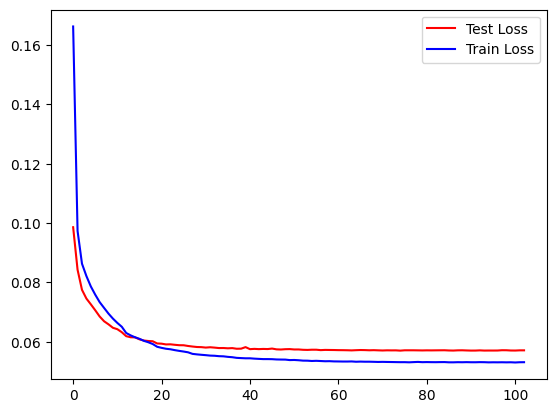

In [ ]:
import matplotlib.pyplot as plt


# Create a plot
plt.plot(ts_loss,'r',label='Test Loss')
plt.plot(tr_loss,'b',label='Train Loss')
plt.legend(loc='upper right')
# Display the plot
plt.show()
